# Часть 2. Событийный анализ


## Задание

По данным проанализировать, влияет ли раскрытие о созыве СД с дивидендом в повестке на котировки:
1. Каждой из данных вам компаний по отдельности?

2. На все компании в среднем?

3. Оцените количественно влияние раскрытия на котировку (в %)

4. Оцените какой объем в рублях можно купить в данных акциях в момент раскрытия

5. Оцените потенциальный PnL стратегии "купить в момент выхода раскрытия о созыве СД с дивидендом в повестке"


Вторую часть делайте в питон-ноутбуке. Методы и статистики по значениям которых вы будете делать выводы выберете сами и коротко обоснуйте ваш выбор.
Тут не требуется каких-то сложных подходов, хитрых статистических тестов итд, но если хотите можете как угодно оценивать влияние.
Посмотрите разные временные промежутки для оценки влияния, интересует краткосрочное влияние - секунды-минуты-часы с момента выхода корп события.

## Данные

Вы получили датасет для 4х публичных российских компаний. Датасет для каждой компании состоит из двух файлов: `<TICKER>_disclosures.json`, `<TICKER>_candles.parquet`.
В первом перечислены анонсы заседаний совета директоров компании со словом дивиденд в повестке заседания.
Пример:
```json
[
  {
    "type": "Проведение заседания совета директоров (наблюдательного совета) и его повестка дня",
    "date": "2025-06-03",
    "time": "12:05:45",
    "body": "Сообщение о существенном факте о проведении заседания совета директоров (наблюдательного совета) эмитента и его повестке дня
            ...
            Е.В. Сердюков\t\n\t(подпись)\t\t\n3.2. Дата\t“\t02\t”\t июня\t2025\tг.\t\t\n\n"
  },
]
```
Во втором лежат секундные свечи. За +-5 дней от дня релиза каждого из перечисленных корпоративных событий этой компании.

In [36]:
import json
from pathlib import Path

import pandas as pd
import pyarrow.parquet as pq
import matplotlib.pyplot as plt


In [37]:
DATA_DIR = Path("homework/01_company_analysis/data")
if not DATA_DIR.exists():
    DATA_DIR = Path("data")

tickers = ["GAZP", "HNFG", "KZOS", "ROLO"]
events = []

for ticker in tickers:
    path = DATA_DIR / f"{ticker}_disclosures.json"
    with path.open(encoding="utf-8") as file:
        for disclosure in json.load(file):
            events.append({
                "ticker": ticker,
                "date": disclosure["date"],
                "time": disclosure["time"],
                "type": disclosure["type"],
            })

events.sort(key=lambda event: (event["date"], event["time"], event["ticker"]))
print(f"Всего событий: {len(events)}")
for ticker in tickers:
    ticker_events = [event for event in events if event["ticker"] == ticker]
    print(f"{ticker}: {len(ticker_events)}")

for event in events:
    print(event["ticker"], event["date"], event["time"])

Всего событий: 15
GAZP: 4
HNFG: 3
KZOS: 4
ROLO: 4
GAZP 2023-05-15 18:51:12
ROLO 2023-05-15 19:00:00
KZOS 2023-05-17 18:05:14
HNFG 2024-04-02 09:55:00
ROLO 2024-05-14 19:00:00
GAZP 2024-05-17 15:18:50
KZOS 2024-05-17 16:23:04
ROLO 2025-03-28 15:24:34
GAZP 2025-05-14 17:31:07
HNFG 2025-05-15 15:46:59
KZOS 2025-05-19 17:37:49
ROLO 2026-04-09 16:46:19
GAZP 2026-05-12 14:40:43
KZOS 2026-05-12 15:35:07
HNFG 2026-05-15 16:31:11


Это список когда и по каким акциям появились новости 

In [38]:
for ticker in tickers:
    path = DATA_DIR / f"{ticker}_candles.parquet"
    times = pq.read_table(path, columns=["time"])["time"].to_pylist()
    print(f"{ticker}: {len(times):,} свечей, {times[0]} — {times[-1]}")
    print("  колонки:", pq.read_schema(path).names)


GAZP: 712,743 свечей, 2023-05-15 09:59:41+03:00 — 2026-05-12 23:49:57+03:00
  колонки: ['time', 'open', 'high', 'low', 'close', 'volume']
HNFG: 31,038 свечей, 2024-04-02 09:59:54+03:00 — 2026-05-15 23:49:25+03:00
  колонки: ['time', 'open', 'high', 'low', 'close', 'volume']
KZOS: 12,857 свечей, 2023-05-17 09:59:36+03:00 — 2026-05-12 22:54:12+03:00
  колонки: ['time', 'open', 'high', 'low', 'close', 'volume']
ROLO: 36,462 свечей, 2023-05-15 09:59:52+03:00 — 2026-04-09 23:46:12+03:00
  колонки: ['time', 'open', 'high', 'low', 'close', 'volume']


Беру последнюю свечу строго до времени публикации и первую свечу после него. Свечу с той же секундой исключаем: по секундным данным нельзя понять, была сделка до публикации внутри этой секунды или после. Разница во времени покажет, насколько быстро после новости появились сделки.


In [39]:
candles = pd.concat(
    [
        pd.read_parquet(DATA_DIR / "GAZP_candles.parquet", columns=["time"])[["time"]].assign(ticker="GAZP"),
        pd.read_parquet(DATA_DIR / "HNFG_candles.parquet", columns=["time"])[["time"]].assign(ticker="HNFG"),
        pd.read_parquet(DATA_DIR / "KZOS_candles.parquet", columns=["time"])[["time"]].assign(ticker="KZOS"),
        pd.read_parquet(DATA_DIR / "ROLO_candles.parquet", columns=["time"])[["time"]].assign(ticker="ROLO"),
    ],
    ignore_index=True,
).sort_values("time")
candles["time"] = pd.to_datetime(candles["time"])

event_data = pd.DataFrame(events)
event_data["event_time"] = pd.to_datetime(
    event_data["date"] + " " + event_data["time"]
).dt.tz_localize("Europe/Moscow").astype(candles["time"].dtype)
event_data = event_data.sort_values("event_time").reset_index(drop=True)
event_data["event_id"] = event_data.index

before = pd.merge_asof(
    event_data,
    candles.rename(columns={"time": "time_before"}),
    left_on="event_time",
    right_on="time_before",
    by="ticker",
    direction="backward",
    allow_exact_matches=False,
)
after = pd.merge_asof(
    event_data,
    candles.rename(columns={"time": "time_after"}),
    left_on="event_time",
    right_on="time_after",
    by="ticker",
    direction="forward",
    allow_exact_matches=False,
)

time_gaps = pd.DataFrame({
    "Акция": event_data["ticker"],
    "Время новости": event_data["event_time"].dt.strftime("%d.%m.%Y %H:%M:%S"),
    "До предыдущей сделки, с": (
        event_data["event_time"] - before["time_before"]
    ).dt.total_seconds().round().astype("Int64"),
    "До следующей сделки, с": (
        after["time_after"] - event_data["event_time"]
    ).dt.total_seconds().round().astype("Int64"),
})
display(time_gaps)


,Акция,Время новости,"До предыдущей сделки, с","До следующей сделки, с"
0,GAZP,15.05.2023 18:51:12,108,823
1,ROLO,15.05.2023 19:00:00,897,53979
2,KZOS,17.05.2023 18:05:14,66,4
3,HNFG,02.04.2024 09:55:00,<NA>,294
4,ROLO,14.05.2024 19:00:00,803,53985
5,GAZP,17.05.2024 15:18:50,1,1
6,KZOS,17.05.2024 16:23:04,1,2
7,ROLO,28.03.2025 15:24:34,26,1
8,GAZP,14.05.2025 17:31:07,2,1
9,HNFG,15.05.2025 15:46:59,8,1


### Цена прямо перед публикацией и в первой сделке после неё

Первый сдвиг цены (первая цена после / последняя цена до − 1) × 100%

Если в данных нет сделки до публикации, то оставляю пустое значение


In [40]:
price_candles = pd.concat(
    [
        pd.read_parquet(DATA_DIR / "GAZP_candles.parquet", columns=["time", "close", "volume"]).assign(ticker="GAZP"),
        pd.read_parquet(DATA_DIR / "HNFG_candles.parquet", columns=["time", "close", "volume"]).assign(ticker="HNFG"),
        pd.read_parquet(DATA_DIR / "KZOS_candles.parquet", columns=["time", "close", "volume"]).assign(ticker="KZOS"),
        pd.read_parquet(DATA_DIR / "ROLO_candles.parquet", columns=["time", "close", "volume"]).assign(ticker="ROLO"),
    ],
    ignore_index=True,
).sort_values("time")
price_candles["time"] = pd.to_datetime(price_candles["time"])

pre_prices = pd.merge_asof(
    event_data,
    price_candles[["ticker", "time", "close"]].rename(
        columns={"time": "pre_time", "close": "pre_price"}
    ),
    left_on="event_time",
    right_on="pre_time",
    by="ticker",
    direction="backward",
    allow_exact_matches=False,
)
entries = pd.merge_asof(
    event_data,
    price_candles.rename(columns={
        "time": "entry_time", "close": "entry_price", "volume": "entry_volume"
    }),
    left_on="event_time",
    right_on="entry_time",
    by="ticker",
    direction="forward",
    allow_exact_matches=False,
).merge(pre_prices[["event_id", "pre_time", "pre_price"]], on="event_id")
entries["задержка входа, с"] = (
    entries["entry_time"] - entries["event_time"]
).dt.total_seconds()
entries["первый сдвиг, %"] = (
    entries["entry_price"] / entries["pre_price"] - 1
) * 100

display(entries[[
    "ticker", "event_time", "pre_price", "entry_time", "entry_price",
    "задержка входа, с", "первый сдвиг, %",
]].rename(columns={
    "ticker": "Акция", "event_time": "Время новости", "pre_price": "Цена до, руб",
    "entry_time": "Время входа", "entry_price": "Цена после, руб",
}).round({"Цена до, руб": 2, "Цена после, руб": 2, "первый сдвиг, %": 2}))


,Акция,Время новости,"Цена до, руб",Время входа,"Цена после, руб","задержка входа, с","первый сдвиг, %"
0,GAZP,2023-05-15 18:51:12+03:00,173.90,2023-05-15 19:04:55+03:00,176.69,823.0,1.60
1,ROLO,2023-05-15 19:00:00+03:00,0.73,2023-05-16 09:59:39+03:00,0.74,53979.0,1.03
2,KZOS,2023-05-17 18:05:14+03:00,105.00,2023-05-17 18:05:18+03:00,105.20,4.0,0.19
3,HNFG,2024-04-02 09:55:00+03:00,NaN,2024-04-02 09:59:54+03:00,712.00,294.0,NaN
4,ROLO,2024-05-14 19:00:00+03:00,1.20,2024-05-15 09:59:45+03:00,1.20,53985.0,0.25
5,GAZP,2024-05-17 15:18:50+03:00,155.52,2024-05-17 15:18:51+03:00,155.60,1.0,0.05
6,KZOS,2024-05-17 16:23:04+03:00,115.40,2024-05-17 16:23:06+03:00,116.30,2.0,0.78
7,ROLO,2025-03-28 15:24:34+03:00,0.71,2025-03-28 15:24:35+03:00,0.72,1.0,1.21
8,GAZP,2025-05-14 17:31:07+03:00,145.68,2025-05-14 17:31:08+03:00,145.94,1.0,0.18
9,HNFG,2025-05-15 15:46:59+03:00,606.00,2025-05-15 15:47:00+03:00,606.00,1.0,0.00


Проверяю 10 и 30 секунд, затем 1, 5, 15 и 60 минут уже **после первой сделки после новости**. Для каждого срока беру последнюю известную цену, а если за интервал новых сделок не было - цена остаётся прежней. Таким образом мы не подсматриваем в будущее

In [41]:
horizon_labels = {
    10: "10 сек", 30: "30 сек", 60: "1 мин",
    300: "5 мин", 900: "15 мин", 3600: "60 мин",
}
horizons = pd.DataFrame({"секунд после входа": list(horizon_labels)})
targets = entries[
    ["event_id", "ticker", "event_time", "entry_time", "entry_price"]
].merge(horizons, how="cross")
targets["целевое время"] = (
    targets["entry_time"]
    + pd.to_timedelta(targets["секунд после входа"], unit="s")
).astype(price_candles["time"].dtype)

future_prices = pd.merge_asof(
    targets.sort_values("целевое время"),
    price_candles[["ticker", "time", "close"]].rename(
        columns={"time": "время свечи", "close": "цена после"}
    ),
    left_on="целевое время",
    right_on="время свечи",
    by="ticker",
    direction="backward",
)
future_prices["доходность, %"] = (
    future_prices["цена после"] / future_prices["entry_price"] - 1
) * 100
future_prices["давность цены, с"] = (
    future_prices["целевое время"] - future_prices["время свечи"]
).dt.total_seconds()


## 1. Как раскрытие влияет на каждую компанию?


Среднее изменение показывает общий масштаб реакции, медиана — результат типичного события без сильного влияния одного скачка. Событий всего 3–4 на компанию, поэтому эти цифры описывают выборку, но не доказывают устойчивый эффект или причинную связь, так как цену могли менять другие новости и общий рынок


In [42]:
first_move = entries[["ticker", "первый сдвиг, %"]].rename(columns={
    "ticker": "Акция", "первый сдвиг, %": "Доходность, %"
})
first_move["Интервал"] = "Первая сделка"

later_moves = future_prices[[
    "ticker", "секунд после входа", "доходность, %"
]].rename(columns={"ticker": "Акция", "доходность, %": "Доходность, %"})
later_moves["Интервал"] = later_moves["секунд после входа"].map(horizon_labels)

summary_data = pd.concat([first_move, later_moves], ignore_index=True)
summary_data["Интервал"] = pd.Categorical(
    summary_data["Интервал"],
    categories=["Первая сделка", *horizon_labels.values()],
    ordered=True,
)
summary_by_company = (
    summary_data.groupby(["Акция", "Интервал"], observed=True)
    .agg(
        средняя=("Доходность, %", "mean"),
        медиана=("Доходность, %", "median"),
        положительных=("Доходность, %", lambda values: values.gt(0).sum()),
        событий=("Доходность, %", "count"),
    )
    .rename(columns={
        "средняя": "Средняя, %", "медиана": "Медиана, %",
        "положительных": "С ростом", "событий": "Всего",
    })
    .round(2)
)
summary_all = (
    summary_data.groupby("Интервал", observed=True)
    .agg(
        средняя=("Доходность, %", "mean"),
        медиана=("Доходность, %", "median"),
        положительных=("Доходность, %", lambda values: values.gt(0).sum()),
        событий=("Доходность, %", "count"),
    )
    .rename(columns={
        "средняя": "Средняя, %", "медиана": "Медиана, %",
        "положительных": "С ростом", "событий": "Всего",
    })
    .round(2)
)
print("По каждой компании:")
display(summary_by_company)


По каждой компании:


Средняя, %  Медиана, %  С ростом  Всего
Акция Интервал                                              
GAZP  Первая сделка        0.46        0.11         3      4
      10 сек               0.02        0.09         3      4
      30 сек               0.19        0.22         3      4
      1 мин                0.30        0.23         4      4
      5 мин                0.30        0.31         4      4
      15 мин               0.29        0.40         3      4
      60 мин               0.55        0.49         2      4
HNFG  Первая сделка        0.02        0.02         1      2
      10 сек               0.27        0.00         1      3
      30 сек               0.27        0.00         1      3
      1 мин                0.22        0.05         2      3
      5 мин               -0.12        0.10         2      3
      15 мин               0.13       -0.15         1      3
      60 мин               0.25       -0.05         1      3
KZOS  Первая сделка        0.26        0.22         3      4
      10 сек               0.51        0.17         3      4
      30 сек              -0.04        0.00         1      4
      1 мин               -0.03       -0.06         1      4
      5 мин                0.16       -0.13         1      4
      15 мин              -0.20       -0.02         2      4
      60 мин              -0.24       -0.32         1      4
ROLO  Первая сделка        0.65        0.64         4      4
      10 сек              -0.20        0.00         0      4
      30 сек               0.03       -0.03         1      4
      1 мин               -0.13       -0.01         1      4
      5 мин               -0.04        0.25         3      4
      15 мин               0.51       -0.03         2      4
      60 мин               0.90        1.04         2      4

### Вывод по каждой акции

**GAZP:** после входа цена росла во всех четырёх случаях за 1 и 5 минут, среднее изменение на обоих сроках **+0,30%**, через час среднее **+0,55%**, но рост был лишь в 2 случаях из 4

**HNFG:** через час среднее **+0,25%**, медиана **−0,05%**, рост лишь в 1 случае из 3. Для новости 2024 года в файле нет сделки до публикации, поэтому первый скачок цены посчитан только по двум событиям

**KZOS:** первый скачок в среднем **+0,26%**, но через час среднее уже **−0,24%**, рост за час наблюдался только в 1 случае из 4

**ROLO:** первая сделка после новости была дороже в 4 случаях из 4, в среднем на **+0,65%**. Однако через минуту среднее изменение после входа **−0,13%**. Два раскрытия вышли после окончания торгов, и первая следующая сделка состоялась утром и ночной разрыв нельзя приписать только новости


## 2. Как раскрытие влияет на все компании в среднем?


In [43]:
print("По всем событиям:")
display(summary_all)

По всем событиям:


,"Средняя, %","Медиана, %",С ростом,Всего
Интервал,,,,
Первая сделка,0.40,0.18,11,14
10 сек,0.14,0.00,7,15
30 сек,0.10,0.00,6,15
1 мин,0.08,0.05,8,15
5 мин,0.09,0.10,10,15
15 мин,0.18,0.07,8,15
60 мин,0.37,-0.04,6,15


### Вывод по всем компаниям

Первый скачок в среднем **+0,40%** по 14 событиям с доступной ценой до

Через час среднее **+0,37%**, но медиана **−0,04%** и рост был только в **6 из 15** случаев, поэтому в этой выборке нет устойчивого положительного результата через час после входа


## 3. На сколько процентов менялась цена?

Ниже табличка для наглядности


In [44]:
returns = future_prices.pivot(
    index=["event_id", "ticker", "event_time", "entry_time", "entry_price"],
    columns="секунд после входа",
    values="доходность, %",
).reset_index().rename(columns={"ticker": "Акция", **horizon_labels})
returns = returns.merge(
    entries[["event_id", "первый сдвиг, %"]], on="event_id"
)
returns = returns.rename(columns={
    "event_time": "Время новости", "entry_time": "Время входа",
    "entry_price": "Цена входа",
})
returns.columns.name = None
returns["Время новости"] = returns["Время новости"].dt.strftime("%d.%m.%Y %H:%M:%S")
returns["Время входа"] = returns["Время входа"].dt.strftime("%d.%m.%Y %H:%M:%S")
returns["Цена входа"] = returns["Цена входа"].round(2)
returns[["первый сдвиг, %", *horizon_labels.values()]] = returns[
    ["первый сдвиг, %", *horizon_labels.values()]
].round(2)
display(returns.drop(columns="event_id"))


,Акция,Время новости,Время входа,Цена входа,10 сек,30 сек,1 мин,5 мин,15 мин,60 мин,"первый сдвиг, %"
0,GAZP,15.05.2023 18:51:12,15.05.2023 19:04:55,176.69,-0.25,0.27,0.61,0.51,0.43,1.39,1.60
1,ROLO,15.05.2023 19:00:00,16.05.2023 09:59:39,0.74,0.00,-0.05,-0.01,0.70,0.07,2.25,1.03
2,KZOS,17.05.2023 18:05:14,17.05.2023 18:05:18,105.20,1.71,0.19,0.29,1.14,0.48,0.48,0.19
3,HNFG,02.04.2024 09:55:00,02.04.2024 09:59:54,712.00,0.80,0.96,1.07,0.14,1.21,1.46,NaN
4,ROLO,14.05.2024 19:00:00,15.05.2024 09:59:45,1.20,0.00,0.42,0.20,0.47,3.22,3.55,0.25
5,GAZP,17.05.2024 15:18:50,17.05.2024 15:18:51,155.60,0.15,-0.03,0.12,0.24,0.37,-0.04,0.05
6,KZOS,17.05.2024 16:23:04,17.05.2024 16:23:06,116.30,0.09,-0.34,-0.26,-0.26,-1.29,-0.77,0.78
7,ROLO,28.03.2025 15:24:34,28.03.2025 15:24:35,0.72,-0.80,-0.25,-0.72,-1.36,-1.14,-2.05,1.21
8,GAZP,14.05.2025 17:31:07,14.05.2025 17:31:08,145.94,0.13,0.18,0.12,0.05,-0.16,-0.19,0.18
9,HNFG,15.05.2025 15:46:59,15.05.2025 15:47:00,606.00,0.00,-0.13,-0.46,-0.59,-0.66,-0.66,0.00


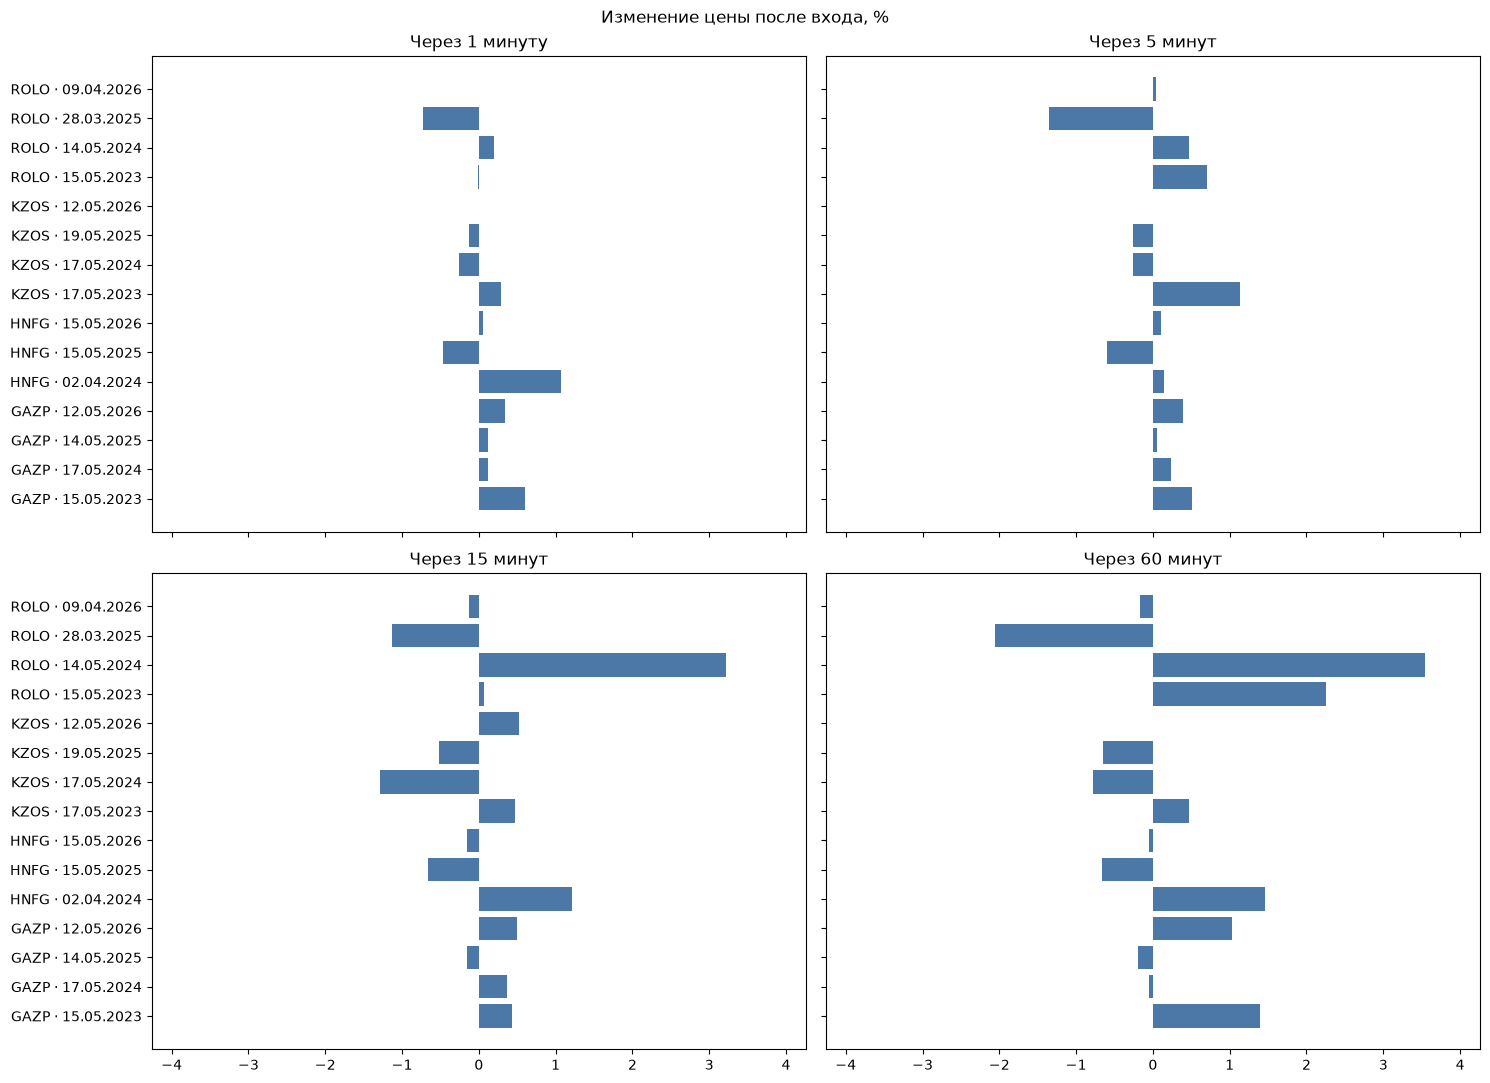

In [45]:
chart_data = (
    future_prices.pivot(
        index=["event_id", "ticker", "event_time"],
        columns="секунд после входа",
        values="доходность, %",
    )
    .reset_index()
    .rename(columns={60: "1 мин", 300: "5 мин", 900: "15 мин", 3600: "60 мин"})
    .sort_values(["ticker", "event_time"])
    .reset_index(drop=True)
)
chart_data.columns.name = None
labels = chart_data["ticker"] + " · " + chart_data["event_time"].dt.strftime("%d.%m.%Y")
limit = chart_data[["1 мин", "5 мин", "15 мин", "60 мин"]].abs().to_numpy().max() * 1.2

fig, axes = plt.subplots(2, 2, figsize=(15, 11), sharex=True, sharey=True)
axes[0, 0].barh(chart_data.index, chart_data["1 мин"], color="#4C78A8")
axes[0, 1].barh(chart_data.index, chart_data["5 мин"], color="#4C78A8")
axes[1, 0].barh(chart_data.index, chart_data["15 мин"], color="#4C78A8")
axes[1, 1].barh(chart_data.index, chart_data["60 мин"], color="#4C78A8")
axes[0, 0].set_title("Через 1 минуту")
axes[0, 1].set_title("Через 5 минут")
axes[1, 0].set_title("Через 15 минут")
axes[1, 1].set_title("Через 60 минут")
axes[0, 0].set_yticks(chart_data.index, labels=labels)
axes[1, 0].set_yticks(chart_data.index, labels=labels)
axes[0, 1].tick_params(axis="y", labelleft=False)
axes[1, 1].tick_params(axis="y", labelleft=False)
axes[0, 0].set_xlim(-limit, limit)
fig.suptitle("Изменение цены после входа, %")
fig.tight_layout()
plt.show()


## 4. Какой объём можно купить в момент раскрытия?


In [46]:
BUDGET_PER_EVENT = 1_000_000
COMMISSION_RATE = 5 / 10_000  # по 0,05% за покупку и продажу
LOT_SIZES = {"GAZP": 10, "HNFG": 1, "KZOS": 10, "ROLO": 1000}

entry_liquidity = entries[[
    "event_id", "ticker", "event_time", "entry_time", "entry_price", "entry_volume"
]].copy()
entry_liquidity["размер лота"] = entry_liquidity["ticker"].map(LOT_SIZES)
entry_liquidity["оборот свечи, руб"] = (
    entry_liquidity["entry_volume"]
    * entry_liquidity["размер лота"]
    * entry_liquidity["entry_price"]
)
entry_liquidity["лотов по бюджету"] = (
    BUDGET_PER_EVENT
    / (entry_liquidity["entry_price"] * entry_liquidity["размер лота"] * (1 + COMMISSION_RATE))
).floordiv(1).astype(int)
entry_liquidity["покупаем, лотов"] = entry_liquidity[[
    "entry_volume", "лотов по бюджету"
]].min(axis=1).astype(int)
entry_liquidity["вложено_руб"] = (
    entry_liquidity["покупаем, лотов"]
    * entry_liquidity["размер лота"]
    * entry_liquidity["entry_price"]
    * (1 + COMMISSION_RATE)
)
entry_liquidity["полный бюджет"] = (
    entry_liquidity["entry_volume"] >= entry_liquidity["лотов по бюджету"]
)

event_liquidity = entry_liquidity[[
    "ticker", "event_time", "entry_time", "entry_volume", "оборот свечи, руб",
    "покупаем, лотов", "вложено_руб", "полный бюджет",
]].rename(columns={
    "ticker": "Акция", "event_time": "Время новости", "entry_time": "Время входа",
    "entry_volume": "Лотов в свече", "покупаем, лотов": "Покупаем лотов",
    "вложено_руб": "Можно вложить, руб", "полный бюджет": "Хватает на 1 млн Р",
})
print("Оборот первой свечи и верхняя оценка покупки:")
display(event_liquidity.assign(**{
    "оборот свечи, руб": event_liquidity["оборот свечи, руб"].round(0),
    "Можно вложить, руб": event_liquidity["Можно вложить, руб"].round(0),
}))

liquidity_summary = (
    entry_liquidity.groupby("ticker")
    .agg(
        событий=("event_id", "count"),
        средний_оборот=("оборот свечи, руб", "mean"),
        медианный_оборот=("оборот свечи, руб", "median"),
        средняя_покупка=("вложено_руб", "mean"),
        полный_бюджет=("полный бюджет", "sum"),
    )
    .rename_axis("Акция")
    .rename(columns={
        "событий": "Событий", "средний_оборот": "Средний оборот, руб",
        "медианный_оборот": "Медианный оборот, руб",
        "средняя_покупка": "Средняя покупка, руб",
        "полный_бюджет": "С полным бюджетом",
    })
)
print("Сводка по акциям:")
display(liquidity_summary.round(0))


Оборот первой свечи и верхняя оценка покупки:


,Акция,Время новости,Время входа,Лотов в свече,"оборот свечи, руб",Покупаем лотов,"Можно вложить, руб",Хватает на 1 млн Р
0,GAZP,2023-05-15 18:51:12+03:00,2023-05-15 19:04:55+03:00,27026,47752239.0,565,998798.0,True
1,ROLO,2023-05-15 19:00:00+03:00,2023-05-16 09:59:39+03:00,388,286344.0,388,286487.0,False
2,KZOS,2023-05-17 18:05:14+03:00,2023-05-17 18:05:18+03:00,863,907876.0,863,908330.0,False
3,HNFG,2024-04-02 09:55:00+03:00,2024-04-02 09:59:54+03:00,1023,728376.0,1023,728740.0,False
4,ROLO,2024-05-14 19:00:00+03:00,2024-05-15 09:59:45+03:00,125,150025.0,125,150100.0,False
5,GAZP,2024-05-17 15:18:50+03:00,2024-05-17 15:18:51+03:00,18943,29475308.0,642,999451.0,True
6,KZOS,2024-05-17 16:23:04+03:00,2024-05-17 16:23:06+03:00,1200,1395600.0,859,999517.0,True
7,ROLO,2025-03-28 15:24:34+03:00,2025-03-28 15:24:35+03:00,1495,1078194.0,1385,999361.0,True
8,GAZP,2025-05-14 17:31:07+03:00,2025-05-14 17:31:08+03:00,42936,62660798.0,684,998729.0,True
9,HNFG,2025-05-15 15:46:59+03:00,2025-05-15 15:47:00+03:00,1247,755682.0,1247,756060.0,False


Сводка по акциям:


,Событий,"Средний оборот, руб","Медианный оборот, руб","Средняя покупка, руб",С полным бюджетом
Акция,,,,,
GAZP,4,35019031.0,38613774.0,796212.0,3
HNFG,3,550559.0,728376.0,550834.0,0
KZOS,4,622367.0,545776.0,523483.0,1
ROLO,4,379372.0,218184.0,359719.0,1


### Оценка доступного объёма

В **volume** указано количество лотов в первой секундной свече **после** новости. Умножаем его на число акций в лоте и цену и получаем оборот свечи в рублях. Дальше считаем, сколько целых лотов помещается в бюджет **1 млн Р с учётом комиссии за покупку**, и берём меньшее из двух чисел: лимит бюджета или число лотов в свече (потом я посмотрел и другие лимиты, это интересно)

По пяти событиям оборота первой свечи достаточно для покупки примерно на весь миллион, по остальным десяти объём ограничивает сделку. Самые маленькие оценки — **2 317 Р** для KZOS 12.05.2026 и **2 927 Р** для ROLO 09.04.2026

Размеры стандартных лотов: [GAZP — 10](https://www.moex.com/ru/stocks/GAZP), [HNFG — 1](https://www.moex.com/ru/stocks/hnfg), [KZOS — 10](https://www.moex.com/ru/stocks/kzos), [ROLO — 1 000](https://www.moex.com/ru/stocks/rolo)


## 5. Какой PnL могла дать стратегия?


На каждую новость выделяем **до 1 млн Р**, включая комиссию за покупку. Входим по первой свече строго после времени раскрытия, покупаем только целые лоты и не больше объёма этой свечи, выходим по последней известной цене к выбранному сроку — через 10, 30 секунд, 1, 5, 15 или 60 минут после входа

Комиссия составляет **5 бп (0,05%) от суммы покупки и 5 бп от суммы продажи**. Это ставка тарифа «Трейдер» Т‑Инвестиций [Источник: тарифы Т‑Инвестиций](https://www.tbank.ru/invest/tariffs/)

PnL = акции × (цена выхода − цена входа) − комиссии за покупку и продажу

Доходность считаем от реально вложенной суммы с комиссией за покупку

#### PnL каждой сделки


In [47]:
pnl_data = future_prices.merge(
    entry_liquidity[["event_id", "покупаем, лотов", "размер лота", "вложено_руб"]],
    on="event_id",
)
pnl_data["акций"] = pnl_data["покупаем, лотов"] * pnl_data["размер лота"]
pnl_data["комиссия_руб"] = (
    pnl_data["акций"] * (pnl_data["entry_price"] + pnl_data["цена после"]) * COMMISSION_RATE
)
pnl_data["pnl_руб"] = (
    pnl_data["акций"] * (pnl_data["цена после"] - pnl_data["entry_price"])
    - pnl_data["комиссия_руб"]
)



#### PnL по компаниям


In [48]:
pnl_by_company = (
    pnl_data.groupby(["ticker", "секунд после входа"], observed=True)
    .agg(
        сделок=("event_id", "nunique"),
        вложено=("вложено_руб", "sum"),
        комиссия=("комиссия_руб", "sum"),
        pnl=("pnl_руб", "sum"),
        средний_pnl=("pnl_руб", "mean"),
        прибыльных=("pnl_руб", lambda values: values.gt(0).sum()),
    )
    .rename_axis(index=["Акция", "Выход через, с"])
    .rename(columns={
        "сделок": "Сделок", "вложено": "Вложено, руб",
        "комиссия": "Комиссия, руб", "pnl": "Суммарный PnL, руб",
        "средний_pnl": "Средний PnL, руб", "прибыльных": "Прибыльных сделок",
    })
)
pnl_by_company["Доходность, %"] = (
    pnl_by_company["Суммарный PnL, руб"] / pnl_by_company["Вложено, руб"] * 100
)

print("По каждой компании и сроку выхода, после комиссии 5 бп за сторону:")
display(pnl_by_company.round(2))


По каждой компании и сроку выхода, после комиссии 5 бп за сторону:


Сделок  Вложено, руб  Комиссия, руб  Суммарный PnL, руб  \
Акция Выход через, с                                                            
GAZP  10                   4    3184848.63        3183.46            -2786.16   
      30                   4    3184848.63        3185.67             1644.63   
      60                   4    3184848.63        3187.83             5951.27   
      300                  4    3184848.63        3187.63             5554.37   
      900                  4    3184848.63        3186.95             4190.75   
      3600                 4    3184848.63        3190.00            10287.50   
HNFG  10                   3    1652501.84        1654.59             4176.51   
      30                   3    1652501.84        1654.66             4304.14   
      60                   3    1652501.84        1653.86             2712.94   
      300                  3    1652501.84        1650.03            -4949.03   
      900                  3    1652501.84        1653.46             1905.54   
      3600                 3    1652501.84        1654.46             3913.14   
KZOS  10                   4    2093930.44        2101.32            14765.68   
      30                   4    2093930.44        2092.03            -3802.03   
      60                   4    2093930.44        2092.77            -2317.77   
      300                  4    2093930.44        2096.54             5208.46   
      900                  4    2093930.44        2088.13           -11594.13   
      3600                 4    2093930.44        2090.58            -6691.58   
ROLO  10                   4    1438875.68        1434.14            -9467.14   
      30                   4    1438875.68        1437.14            -3460.34   
      60                   4    1438875.68        1434.69            -8375.49   
      300                  4    1438875.68        1432.73           -12286.93   
      900                  4    1438875.68        1434.99            -7776.59   
      3600                 4    1438875.68        1433.79           -10170.79   

                      Средний PnL, руб  Прибыльных сделок  Доходность, %  
Акция Выход через, с                                                      
GAZP  10                       -696.54                  2          -0.09  
      30                        411.16                  3           0.05  
      60                       1487.82                  4           0.19  
      300                      1388.59                  3           0.17  
      900                      1047.69                  3           0.13  
      3600                     2571.88                  2           0.32  
HNFG  10                       1392.17                  1           0.25  
      30                       1434.71                  1           0.26  
      60                        904.31                  1           0.16  
      300                     -1649.68                  1          -0.30  
      900                       635.18                  1           0.12  
      3600                     1304.38                  1           0.24  
KZOS  10                       3691.42                  2           0.71  
      30                       -950.51                  1          -0.18  
      60                       -579.44                  1          -0.11  
      300                      1302.12                  1           0.25  
      900                     -2898.53                  2          -0.55  
      3600                    -1672.90                  1          -0.32  
ROLO  10                      -2366.79                  0          -0.66  
      30                       -865.09                  1          -0.24  
      60                      -2093.87                  1          -0.58  
      300                     -3071.73                  2          -0.85  
      900                     -1944.15                  1          -0.54  
      3600                    -2542.70  

#### PnL по всем событиям


In [49]:
pnl_all = (
    pnl_data.groupby("секунд после входа", observed=True)
    .agg(
        сделок=("event_id", "nunique"),
        вложено=("вложено_руб", "sum"),
        комиссия=("комиссия_руб", "sum"),
        pnl=("pnl_руб", "sum"),
        средний_pnl=("pnl_руб", "mean"),
        медианный_pnl=("pnl_руб", "median"),
        прибыльных=("pnl_руб", lambda values: values.gt(0).sum()),
    )
    .rename_axis("Выход через, с")
    .rename(columns={
        "сделок": "Сделок", "вложено": "Вложено, руб",
        "комиссия": "Комиссия, руб", "pnl": "Суммарный PnL, руб",
        "средний_pnl": "Средний PnL, руб", "медианный_pnl": "Медианный PnL, руб",
        "прибыльных": "Прибыльных сделок",
    })
)
pnl_all["Доходность, %"] = (
    pnl_all["Суммарный PnL, руб"] / pnl_all["Вложено, руб"] * 100
)

print("По всем 15 событиям:")
display(pnl_all.round(2))


По всем 15 событиям:


,Сделок,"Вложено, руб","Комиссия, руб","Суммарный PnL, руб","Средний PnL, руб","Медианный PnL, руб",Прибыльных сделок,"Доходность, %"
"Выход через, с",,,,,,,,
10,15,8370156.59,8373.50,6688.90,445.93,-80.73,5,0.08
30,15,8370156.59,8369.50,-1313.60,-87.57,-2.93,6,-0.02
60,15,8370156.59,8369.14,-2029.04,-135.27,-2.32,7,-0.02
300,15,8370156.59,8366.92,-6473.12,-431.54,-0.50,7,-0.08
900,15,8370156.59,8363.52,-13274.42,-884.96,-6.52,7,-0.16
3600,15,8370156.59,8368.83,-2661.73,-177.45,-7.72,6,-0.03


#### PnL каждой сделки через час


In [50]:
hour_trades = pnl_data.loc[
    pnl_data["секунд после входа"] == 3600,
    ["ticker", "event_time", "вложено_руб", "pnl_руб"],
].sort_values("event_time").rename(columns={
    "ticker": "Акция", "event_time": "Время новости",
    "вложено_руб": "Вложено, руб", "pnl_руб": "PnL через час, руб",
})
print("Часовой результат по каждому событию:")
display(hour_trades.assign(**{
    "Вложено, руб": hour_trades["Вложено, руб"].round(2),
    "PnL через час, руб": hour_trades["PnL через час, руб"].round(2),
}))


Часовой результат по каждому событию:


,Акция,Время новости,"Вложено, руб","PnL через час, руб"
5,GAZP,2023-05-15 18:51:12+03:00,998797.65,12893.75
11,ROLO,2023-05-15 19:00:00+03:00,286487.17,6151.24
17,KZOS,2023-05-17 18:05:14+03:00,908329.94,3404.97
23,HNFG,2024-04-02 09:55:00+03:00,728740.19,9905.50
29,ROLO,2024-05-14 19:00:00+03:00,150100.01,5172.31
35,GAZP,2024-05-17 15:18:50+03:00,999451.48,-1448.13
41,KZOS,2024-05-17 16:23:04+03:00,999516.51,-8726.15
47,ROLO,2025-03-28 15:24:34+03:00,999361.43,-21486.61
53,GAZP,2025-05-14 17:31:07+03:00,998728.71,-2912.47
59,HNFG,2025-05-15 15:46:59+03:00,756059.84,-5741.19


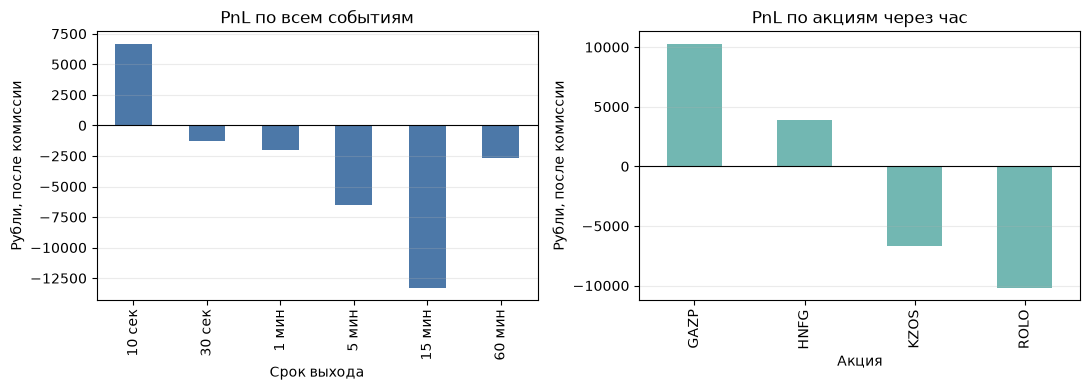

In [51]:
hourly_by_company = pnl_by_company.xs(3600, level="Выход через, с")["Суммарный PnL, руб"]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

pnl_all["Суммарный PnL, руб"].rename(index=horizon_labels).plot.bar(
    ax=axes[0], color="#4C78A8"
)
axes[0].axhline(0, color="black", linewidth=0.8)
axes[0].set_title("PnL по всем событиям")
axes[0].set_xlabel("Срок выхода")
axes[0].set_ylabel("Рубли, после комиссии")
axes[0].grid(axis="y", alpha=0.25)

hourly_by_company.plot.bar(ax=axes[1], color="#72B7B2")
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].set_title("PnL по акциям через час")
axes[1].set_xlabel("Акция")
axes[1].set_ylabel("Рубли, после комиссии")
axes[1].grid(axis="y", alpha=0.25)

fig.tight_layout()
plt.show()


### Что получилось

Я взял лимит **до 1 млн Р на каждую новость**, но купить на весь миллион получилось только в **5 из 15** случаев, а в остальных не хватило объёма в первой свече. Если сложить покупки за все даты, получится **8,37 млн Р** (сумма всех покупочек)

Если продавать через **10 секунд после покупки**, общий результат после комиссий — **+6 689 Р**, хотя в плюсе только **5 сделок из 15**. Через **15 минут** результат **−13 274 Р**, через **час — −2 662 Р** (в общем, все есть в таблице выше)

За час GAZP принёс **+10 288 Р**, HNFG — **+3 913 Р**, а KZOS и ROLO дали **−6 692 Р** и **−10 171 Р**. В итоге прибыльными оказались только **6 сделок из 15**. Получается, идея «купить после новости и продать через час» на этих данных **не сработала**

Но это расчёт по свечам, а не реальные сделки, и не знаем, удалось бы купить и продать весь объём по указанной цене. У некоторых неликвидных акций к моменту выхода последняя сделка была почти **19 минут назад**, так что настоящая цена продажи может отличаться


### Разный бюджет! (100 тысяч, 500 тысяч и 1 млн рублей)

Повторяю те же самые сделки с теми же ценами входа и выхода, сроками и комиссией, НОО меняю только верхний предел покупки на одно событие. Деньги после выхода из одной сделки можно использовать снова, поэтому сумма покупок за 15 событий может превышать начальный бюджет

Сравнение важно, потому что увеличение бюджета не обязательно одинаково увеличивает позиции во всех событиях, то есть рост прибыли (убытка) вообще не обязан быть пропорциональным!


In [52]:
budgets = pd.DataFrame({"Бюджет, руб": [100_000, 500_000, 1_000_000]})
scenario_entries = entries[[
    "event_id", "ticker", "event_time", "entry_price", "entry_volume"
]].merge(budgets, how="cross")
scenario_entries["размер лота"] = scenario_entries["ticker"].map(LOT_SIZES)
scenario_entries["лотов по бюджету"] = (
    scenario_entries["Бюджет, руб"]
    / (scenario_entries["entry_price"] * scenario_entries["размер лота"] * (1 + COMMISSION_RATE))
).floordiv(1).astype(int)
scenario_entries["покупаем, лотов"] = scenario_entries[[
    "entry_volume", "лотов по бюджету"
]].min(axis=1).astype(int)
scenario_entries["акций"] = scenario_entries["покупаем, лотов"] * scenario_entries["размер лота"]
scenario_entries["вложено, руб"] = (
    scenario_entries["акций"] * scenario_entries["entry_price"] * (1 + COMMISSION_RATE)
)
scenario_entries["хватает объёма"] = (
    scenario_entries["entry_volume"] >= scenario_entries["лотов по бюджету"]
)

scenario_trades = future_prices.merge(
    scenario_entries[[
        "event_id", "Бюджет, руб", "акций", "вложено, руб"
    ]],
    on="event_id",
)
scenario_trades["комиссия, руб"] = (
    scenario_trades["акций"]
    * (scenario_trades["entry_price"] + scenario_trades["цена после"])
    * COMMISSION_RATE
)
scenario_trades["PnL, руб"] = (
    scenario_trades["акций"]
    * (scenario_trades["цена после"] - scenario_trades["entry_price"])
    - scenario_trades["комиссия, руб"]
)

scenario_summary = scenario_trades.groupby([
    "Бюджет, руб", "секунд после входа"
]).agg(
    сделок=("event_id", "nunique"),
    вложено=("вложено, руб", "sum"),
    комиссия=("комиссия, руб", "sum"),
    pnl=("PnL, руб", "sum"),
    прибыльных=("PnL, руб", lambda values: values.gt(0).sum()),
).rename(columns={
    "сделок": "Сделок", "вложено": "Сумма покупок, руб",
    "комиссия": "Комиссия, руб", "pnl": "PnL, руб",
    "прибыльных": "Прибыльных сделок",
})
scenario_summary["Доходность на оборот, %"] = (
    scenario_summary["PnL, руб"] / scenario_summary["Сумма покупок, руб"] * 100
)

hourly_summary = scenario_summary.xs(3600, level="секунд после входа").copy()
hourly_summary["С полным бюджетом"] = scenario_entries.groupby(
    "Бюджет, руб"
)["хватает объёма"].sum()
print("Итог продажи через час:")
display(hourly_summary.round(2))

print("PnL на разных сроках выхода:")
scenario_horizons = scenario_summary["PnL, руб"].unstack("Бюджет, руб")
scenario_horizons.index = scenario_horizons.index.map(horizon_labels)
display(scenario_horizons.round(2))


Итог продажи через час:


,Сделок,"Сумма покупок, руб","Комиссия, руб","PnL, руб",Прибыльных сделок,"Доходность на оборот, %",С полным бюджетом
"Бюджет, руб",,,,,,,
100000,15,1298751.75,1300.96,4419.94,6,0.34,13
500000,15,4976177.35,4978.92,5478.28,6,0.11,8
1000000,15,8370156.59,8368.83,-2661.73,6,-0.03,5


PnL на разных сроках выхода:


"Бюджет, руб",100000,500000,1000000
секунд после входа,,,
10 сек,836.13,4710.96,6688.90
30 сек,220.44,300.57,-1313.60
1 мин,-90.61,-422.67,-2029.04
5 мин,-20.94,-2463.25,-6473.12
15 мин,1069.91,-3995.68,-13274.42
60 мин,4419.94,5478.28,-2661.73


И графики для наглядности результатов

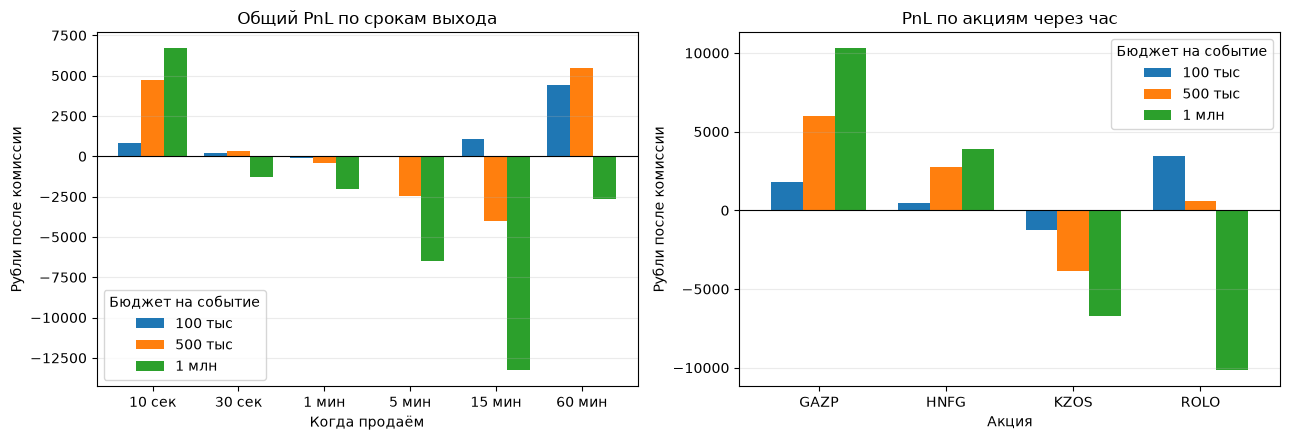

In [53]:
hourly_company = scenario_trades.loc[
    scenario_trades["секунд после входа"] == 3600
].pivot_table(
    index="ticker", columns="Бюджет, руб", values="PnL, руб", aggfunc="sum"
)

budget_names = {100_000: "100 тыс", 500_000: "500 тыс", 1_000_000: "1 млн"}
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
scenario_horizons.rename(columns=budget_names).plot.bar(ax=axes[0], width=0.8)
axes[0].axhline(0, color="black", linewidth=0.8)
axes[0].set_title("Общий PnL по срокам выхода")
axes[0].set_xlabel("Когда продаём")
axes[0].set_ylabel("Рубли после комиссии")
axes[0].legend(title="Бюджет на событие")
axes[0].tick_params(axis="x", rotation=0)
axes[0].grid(axis="y", alpha=0.25)

hourly_company.rename(columns=budget_names).plot.bar(ax=axes[1], width=0.75)
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].set_title("PnL по акциям через час")
axes[1].set_xlabel("Акция")
axes[1].set_ylabel("Рубли после комиссии")
axes[1].legend(title="Бюджет на событие")
axes[1].tick_params(axis="x", rotation=0)
axes[1].grid(axis="y", alpha=0.25)

fig.tight_layout()
plt.show()


Пример с Росолово (ROLO)

,Событие,"Бюджет, руб","Купили на, руб","PnL, руб"
87,14.05.2024,100000,99666.41,3434.42
88,14.05.2024,500000,150100.01,5172.31
89,14.05.2024,1000000,150100.01,5172.31
141,28.03.2025,100000,99575.36,-2140.90
142,28.03.2025,500000,499319.94,-10735.55
143,28.03.2025,1000000,999361.43,-21486.61


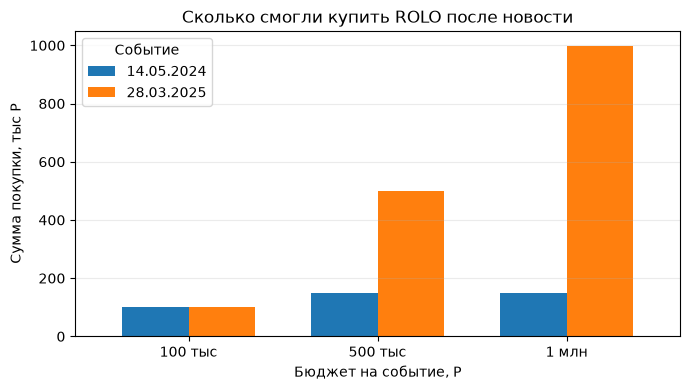

In [54]:
rolo_example = scenario_trades.loc[
    (scenario_trades["ticker"] == "ROLO")
    & (scenario_trades["event_time"].dt.year.isin([2024, 2025]))
    & (scenario_trades["секунд после входа"] == 3600),
    ["event_time", "Бюджет, руб", "вложено, руб", "PnL, руб"],
].copy()
rolo_example["Событие"] = rolo_example["event_time"].dt.strftime("%d.%m.%Y")
display(rolo_example[[
    "Событие", "Бюджет, руб", "вложено, руб", "PnL, руб"
]].rename(columns={"вложено, руб": "Купили на, руб"}).round(2))

rolo_sizes = rolo_example.pivot(
    index="Бюджет, руб", columns="Событие", values="вложено, руб"
)
fig, ax = plt.subplots(figsize=(7, 4))
(rolo_sizes / 1000).plot.bar(ax=ax, width=0.7)
ax.set_title("Сколько смогли купить ROLO после новости")
ax.set_xlabel("Бюджет на событие, Р")
ax.set_ylabel("Сумма покупки, тыс Р")
ax.set_xticklabels(["100 тыс", "500 тыс", "1 млн"], rotation=0)
ax.legend(title="Событие")
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
plt.show()


#### Почему при разных бюджетах разный итог

Я повторил те же сделки, только менял сумму, которую можно потратить на одну новость:

| Бюджет на событие | Всего купили за 15 событий | Комиссии за покупку и продажу | PnL через час | Где хватило объёма |
|---:|---:|---:|---:|---:|
| 100 тыс Р | 1 298 752 Р | 1 301 Р | **+4 420 Р** | 13 из 15 |
| 500 тыс Р | 4 976 177 Р | 4 979 Р | **+5 478 Р** | 8 из 15 |
| 1 млн Р | 8 370 157 Р | 8 369 Р | **−2 662 Р** | 5 из 15 |

Интересно, что при любом лимите через час в плюсе всё те же **6 сделок из 15**, но общий результат разный

Лучше всего это видно на ROLO. После удачной новости в 2024 году в первой свече было акций только примерно на **150 тыс Р**, поэтому при бюджете 500 тыс или 1 млн Р больше купить всё равно не получилось и прибыль осталась **+5 172 Р**, аа после неудачной новости в 2025 году акций хватало почти на миллион. С ростом бюджета убыток вырос с **−2 141 Р** до **−10 736 Р** и **−21 487 Р**. Получается, мы сильнее увеличили убыточную сделку, чем прибыльную :)

Конечно, по 15 новостям нельзя сделать вывод, что бюджет 500 тыс Р всегда будет лучше. К тому же мы считаем по ценам свечей, а в реальной торговле купить и продать весь объём по ним могло не получиться

С бюджетом 100 тыс Р: 12.05.2026 сделки GAZP и KZOS ненадолго пересеклись. Если держать на счёте строго 100 тыс Р, на KZOS денег уже не хватило бы (но там прям копейки)
